t‑SNE: нелинейное вложение, оптимизирует дивергенцию Кульбака–Лейблера между распределениями близостей точек, хорошо показывает локальные кластеры, но медленно, плохо сохраняет глобальные расстояния, чувствительно к perplexity и random_state.

UMAP: основан на теории многобразий и топологии, строит взвешенный граф соседей и оптимизирует кросс‑энтропию; быстрее t‑SNE, лучше сохраняет глобальную структуру, более устойчив к малым изменениям параметров (n_neighbors, min_dist).

TriMAP: ориентирован на сохранение глобальной структуры через тройки точек (anchor, сосед, далёкий), улучшает глобальное расположение кластеров при сохранении локальной структуры.

PaCMAP: управляет соотношением близких, средних и далёких пар, чтобы одновременно хорошо держать локальные кластеры и общую форму; показывает хорошие результаты на омикс‑данных и эмбеддингах.

PHATE: использует диффузионные процессы и потенциал для визуализации непрерывных траекторий (например, дифференцировка клеток), хорошо показывает как кластеры, так и переходы между ними.



In [57]:
%pip install umap-learn trimap pacmap phate scikit-learn seaborn

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances

from sklearn.manifold import TSNE
import umap
import trimap
import pacmap
import phate



In [59]:
iris = load_iris()
X_iris = iris.data
y_iris = iris.target
feature_names_iris = iris.feature_names
print(X_iris.shape, np.unique(y_iris))


(150, 4) [0 1 2]


In [60]:
path = "../data/student_lifestyle_100k.csv"  # замените на свой путь
df = pd.read_csv(path)
df = df[['Age', 'CGPA', 'Sleep_Duration', 'Study_Hours',
         'Social_Media_Hours', 'Physical_Activity', 'Stress_Level','Depression']]
df['Depression'] = df['Depression'].map({False: 0, True: 1})
df = df[:10000]
df.head()

,Age,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level,Depression
0,22,3.50,7.3,3.3,3.4,114,5,0
1,20,2.72,5.5,7.2,6.0,142,2,0
2,20,3.01,5.4,2.3,1.8,137,3,0
3,21,3.63,8.1,2.0,4.6,130,3,0
4,19,3.14,6.8,2.6,4.3,4,6,0


In [61]:
feature_cols = [c for c in df.columns if c != "Depression"]
X_own = df[feature_cols].values
y_own = df["Depression"].values
print(X_own.shape, len(np.unique(y_own)))


(10000, 7) 2


In [62]:
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)
scaler = StandardScaler()
X_own_scaled = scaler.fit_transform(X_own)

Функции для DR и оценки разделения

In [63]:
def run_tsne(X, random_state=42, perplexity=30, learning_rate=200, n_iter=1000):
    tsne = TSNE(
        perplexity=perplexity, random_state=random_state, learning_rate=learning_rate, n_components=2, max_iter=n_iter
    )
    return tsne.fit_transform(X)

def run_umap(X, random_state=42, n_neighbors=15, min_dist=0.1, n_jobs=-1):
    reducer = umap.UMAP(n_components=2, random_state=random_state, n_neighbors=n_neighbors, min_dist=min_dist, n_jobs=n_jobs)
    return reducer.fit_transform(X)

def run_trimap(X, n_inliers=10, n_outliers=5):
    reducer = trimap.TRIMAP(n_inliers=n_inliers, n_outliers=n_outliers, n_dims=2)
    return reducer.fit_transform(X)

def run_pacmap(X, random_state=42, n_neighbors=10):
    reducer = pacmap.PaCMAP(n_components=2, random_state=random_state, n_neighbors=n_neighbors)
    return reducer.fit_transform(X)

def run_phate(X, random_state=42, knn=15):
    phate_op = phate.PHATE(n_components=2, random_state=random_state, knn=knn)
    return phate_op.fit_transform(X)


Функция оценки качества разделения

In [64]:
def separation_score(X_2d, y):
    D = pairwise_distances(X_2d)
    same = D[y[:, None] == y[None, :]]
    diff = D[y[:, None] != y[None, :]]
    return same.mean(), diff.mean(), diff.mean() / same.mean()


In [65]:
# Отрисовка

def plot_embedding(X_2d, y, title):
    plt.figure(figsize=(6, 5))
    sns.scatterplot(
        x=X_2d[:, 0],
        y=X_2d[:, 1],
        hue=y,
        palette="tab10",
        s=30,
        legend="full"
    )
    plt.title(title)
    plt.xticks([])
    plt.yticks([])
    plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Calculating PHATE...
  Running PHATE on 150 observations and 4 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculating affinities...
  Calculating optimal t...
    Automatically selected t = 22
  Calculated optimal t in 0.01 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -1.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.09 seconds.
Calculated PHATE in 0.12 seconds.


g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\graphtools\graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


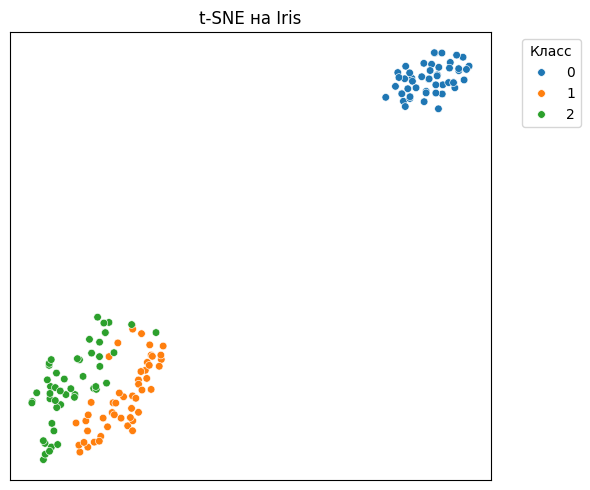

t-SNE: внутрикласс.=3.580, межкласс.=28.091, ratio=7.846


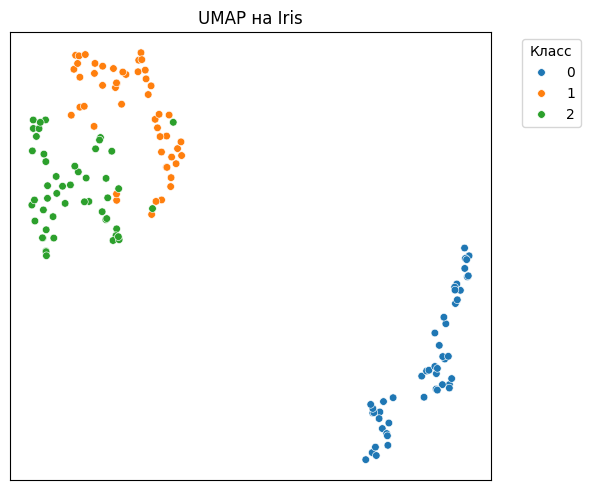

UMAP: внутрикласс.=1.902, межкласс.=10.504, ratio=5.524


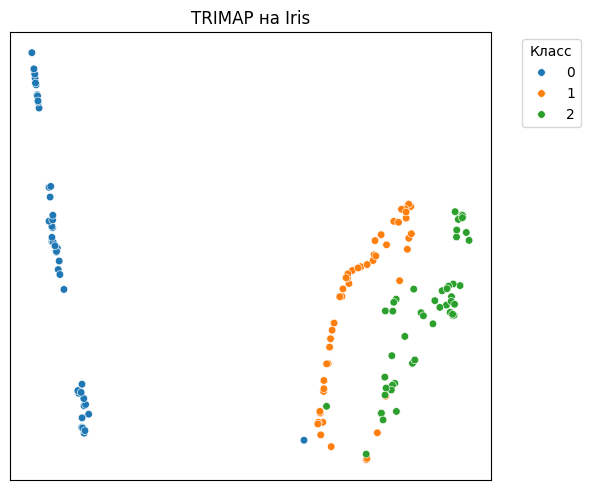

TRIMAP: внутрикласс.=11.176, межкласс.=61.114, ratio=5.468


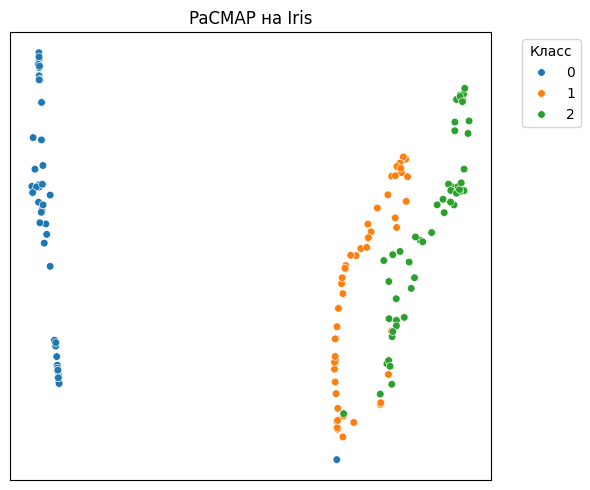

PaCMAP: внутрикласс.=3.470, межкласс.=17.674, ratio=5.093


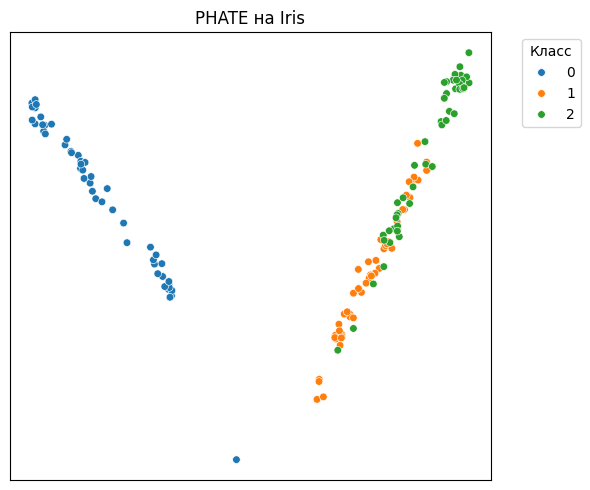

PHATE: внутрикласс.=0.026, межкласс.=0.121, ratio=4.610


In [66]:
X_list = []
names = []

X_tsne_iris = run_tsne(X_iris_scaled, random_state=42)
X_list.append(X_tsne_iris); names.append("t-SNE")

X_umap_iris = run_umap(X_iris_scaled, random_state=42)
X_list.append(X_umap_iris); names.append("UMAP")

X_trimap_iris = run_trimap(X_iris_scaled)
X_list.append(X_trimap_iris); names.append("TRIMAP")

X_pacmap_iris = run_pacmap(X_iris_scaled, random_state=42)
X_list.append(X_pacmap_iris); names.append("PaCMAP")

X_phate_iris = run_phate(X_iris_scaled, random_state=42)
X_list.append(X_phate_iris); names.append("PHATE")

for X_emb, name in zip(X_list, names):
    plot_embedding(X_emb, y_iris, f"{name} на Iris")
    same, diff, ratio = separation_score(X_emb, y_iris)
    print(
        f"{name}: внутрикласс.={same:.3f}, межкласс.={diff:.3f}, ratio={ratio:.3f}"
    )


g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Calculating PHATE...
  Running PHATE on 10000 observations and 7 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculated KNN search in 0.68 seconds.
    Calculating affinities...
    Calculated affinities in 0.15 seconds.
  Calculated graph and diffusion operator in 0.85 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 0.74 seconds.
    Calculating KMeans...
    Calculated KMeans in 2.79 seconds.
  Calculated landmark operator in 3.53 seconds.
  Calculating optimal t...
    Automatically selected t = 23
  Calculated optimal t in 1.95 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.46 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 2.03 seconds.
Calculated PHATE in 9.29 seconds.


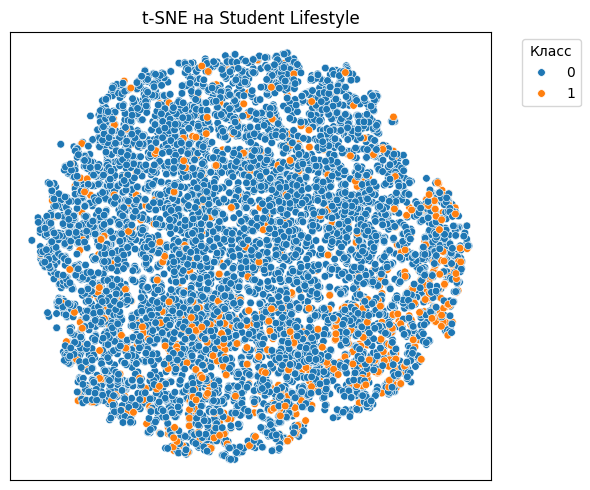

t-SNE: внутрикласс.=68.697, межкласс.=71.826, ratio=1.046


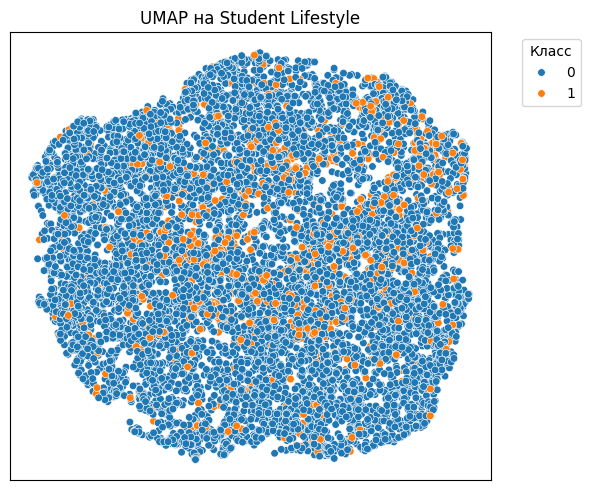

UMAP: внутрикласс.=3.931, межкласс.=3.782, ratio=0.962


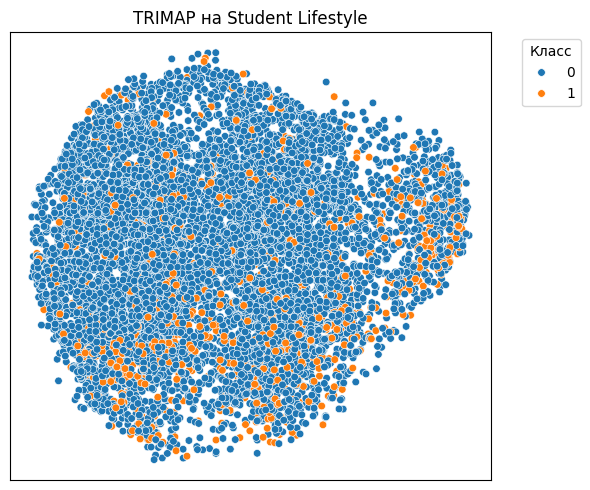

TRIMAP: внутрикласс.=45.769, межкласс.=48.875, ratio=1.068


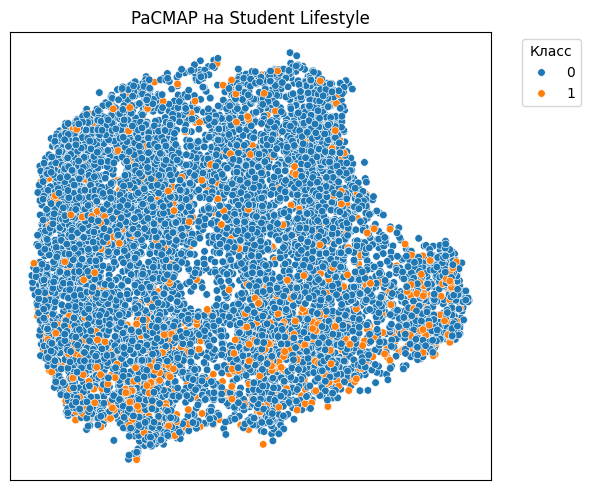

PaCMAP: внутрикласс.=8.036, межкласс.=8.480, ratio=1.055


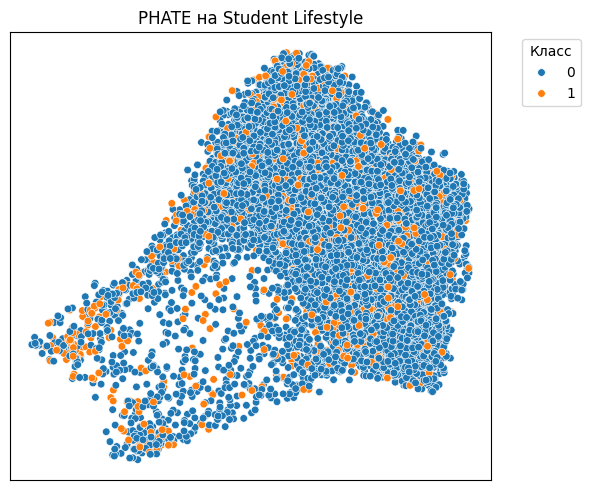

PHATE: внутрикласс.=0.023, межкласс.=0.025, ratio=1.108


In [67]:
X_list = []
names = []

X_tsne = run_tsne(X_own_scaled, random_state=42)
X_list.append(X_tsne); names.append("t-SNE")

X_umap = run_umap(X_own_scaled, random_state=42)
X_list.append(X_umap); names.append("UMAP")

X_trimap = run_trimap(X_own_scaled)
X_list.append(X_trimap); names.append("TRIMAP")

X_pacmap = run_pacmap(X_own_scaled, random_state=42)
X_list.append(X_pacmap); names.append("PaCMAP")

X_phate = run_phate(X_own_scaled, random_state=42)
X_list.append(X_phate); names.append("PHATE")

for X_emb, name in zip(X_list, names):
    plot_embedding(X_emb, y_own, f"{name} на Student Lifestyle")
    same, diff, ratio = separation_score(X_emb, y_own)
    print(
        f"{name}: внутрикласс.={same:.3f}, межкласс.={diff:.3f}, ratio={ratio:.3f}"
    )

Сравнение устойчивости

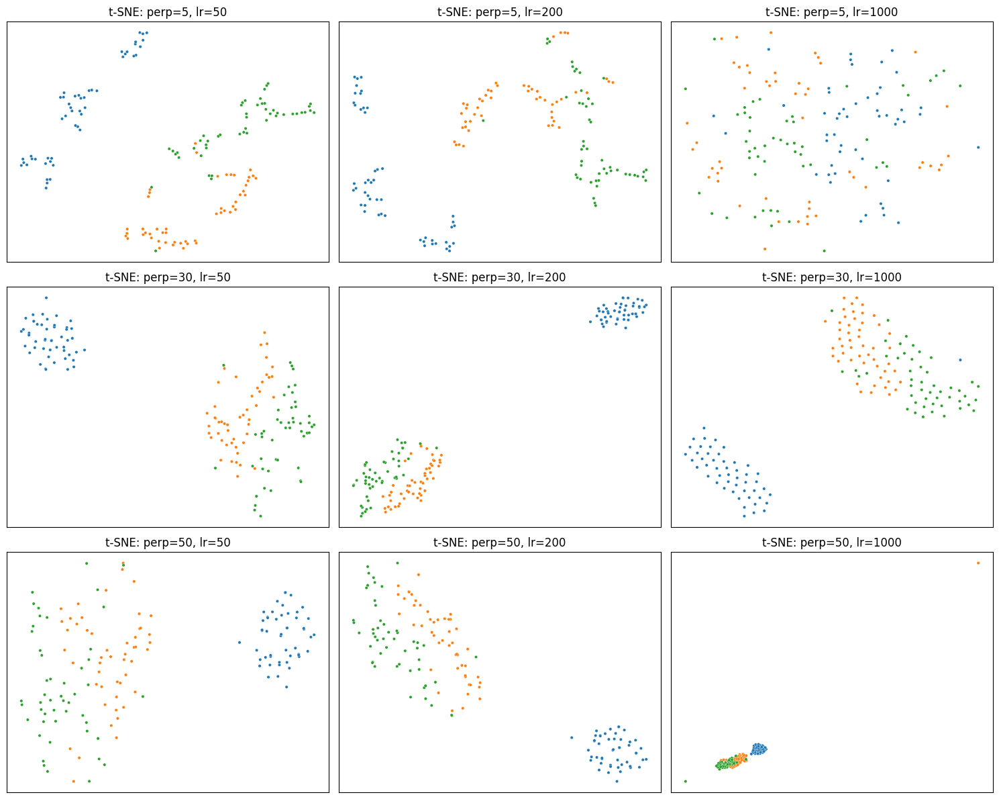

In [70]:
perplexities = [5, 30, 50]
lrs = [50, 200, 1000]

fig, axes = plt.subplots(len(perplexities), len(lrs), figsize=(5*len(lrs), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(lrs):
        X_emb = run_tsne(X_iris_scaled, random_state=42, perplexity=perp, learning_rate=lr)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"t-SNE: perp={perp}, lr={lr}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()


Нужно описать, как меняется форма и расположение кластеров при разных perplexity и learning_rate и что визуализация t‑SNE может сильно меняться.

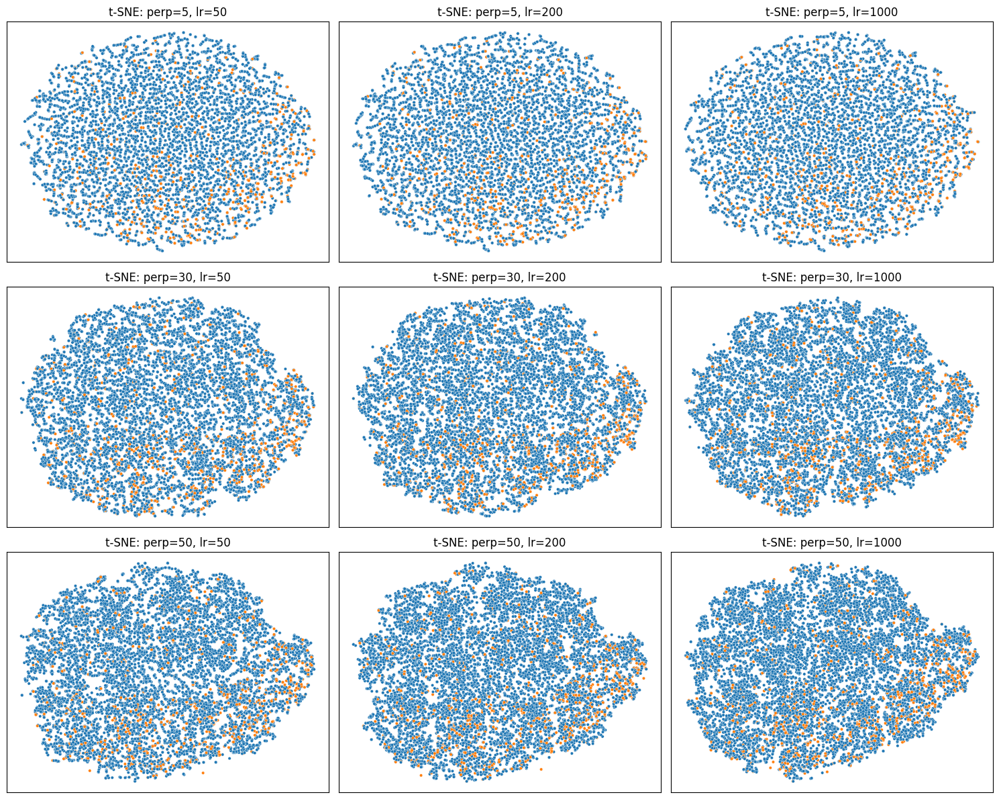

In [73]:
perplexities = [5, 30, 50]
lrs = [50, 200, 1000]

fig, axes = plt.subplots(len(perplexities), len(lrs), figsize=(5*len(lrs), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(lrs):
        X_emb = run_tsne(X_own_scaled, random_state=42, perplexity=perp, learning_rate=lr)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"t-SNE: perp={perp}, lr={lr}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 ove

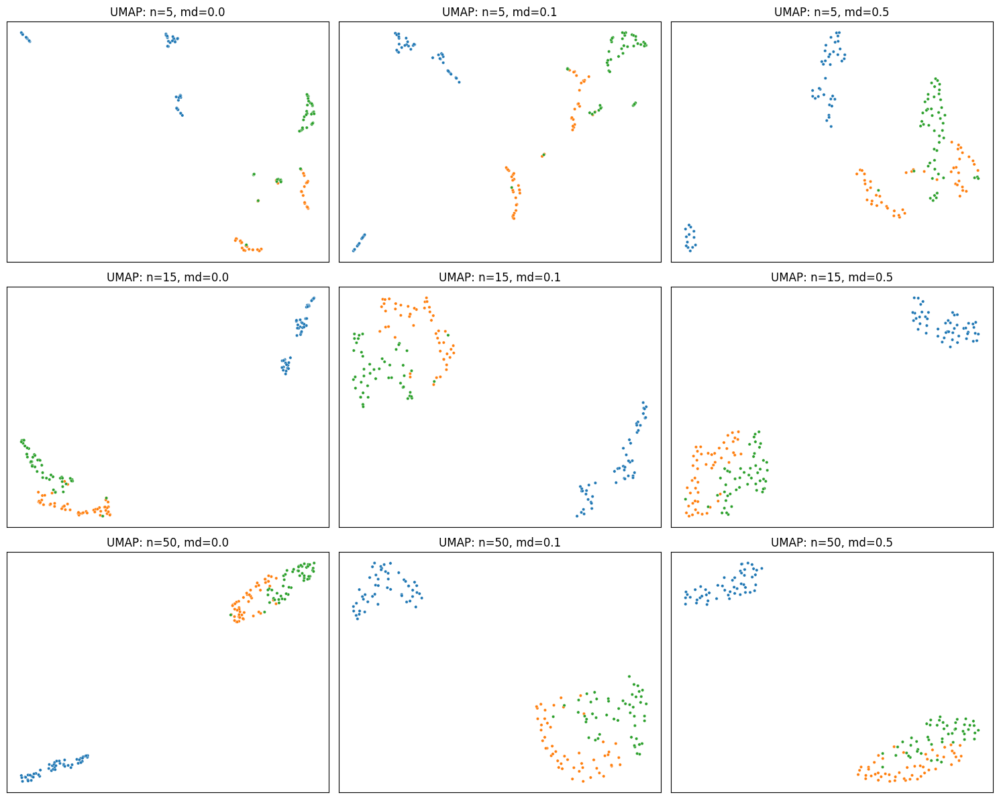

In [74]:
n_neighbors = [5, 15, 50]
md = [0.0, 0.1, 0.5]

fig, axes = plt.subplots(len(n_neighbors), len(md), figsize=(5*len(md), 4*len(n_neighbors)))

for i, n in enumerate(n_neighbors):
    for j, m in enumerate(md):
        X_emb = run_umap(X_iris_scaled, random_state=42, n_neighbors=n, min_dist=m)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"UMAP: n={n}, md={m}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 ove

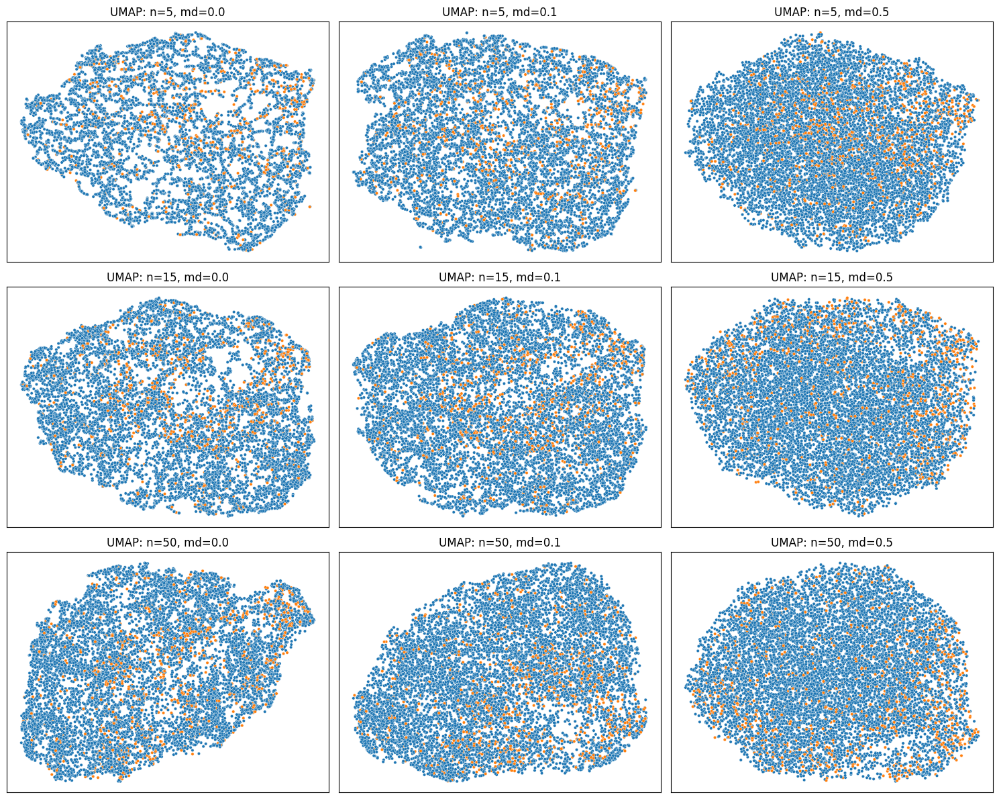

In [75]:
n_neighbors = [5, 15, 50]
md = [0.0, 0.1, 0.5]

fig, axes = plt.subplots(len(n_neighbors), len(md), figsize=(5*len(md), 4*len(n_neighbors)))

for i, n in enumerate(n_neighbors):
    for j, m in enumerate(md):
        X_emb = run_umap(X_own_scaled, random_state=42, n_neighbors=n, min_dist=m)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"UMAP: n={n}, md={m}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

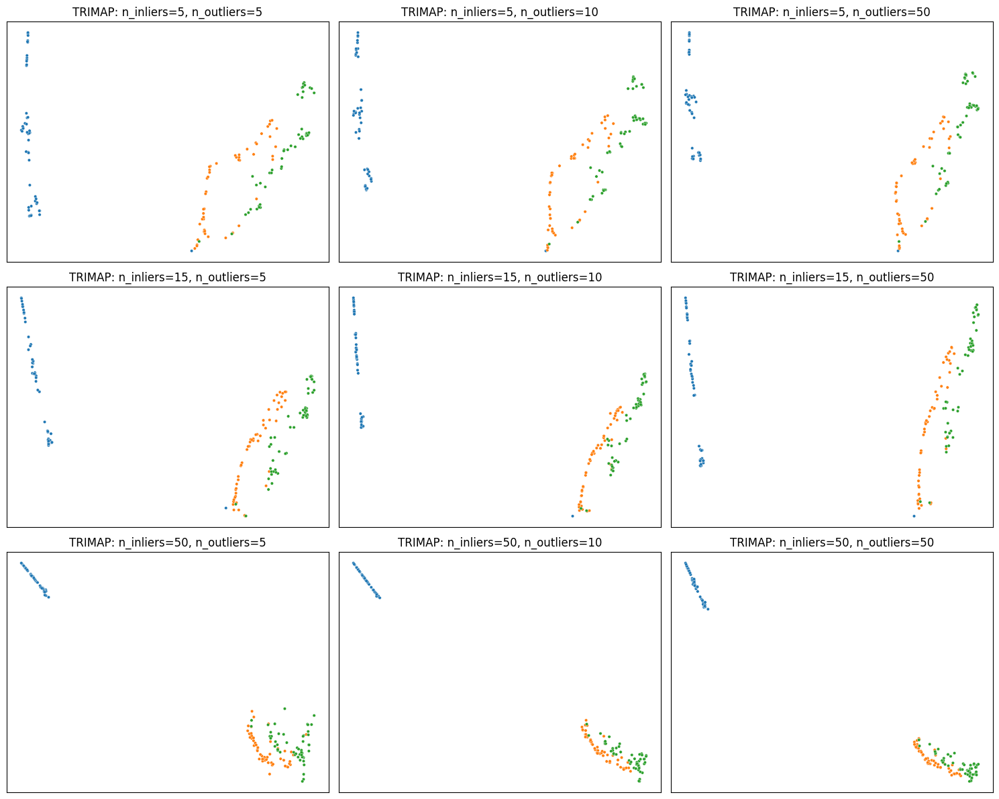

In [76]:
n_inliers = [5, 15, 50]
n_outliers = [5, 10, 50]

fig, axes = plt.subplots(len(n_inliers), len(n_outliers), figsize=(5*len(n_outliers), 4*len(n_inliers)))

for i, n in enumerate(n_inliers):
    for j, m in enumerate(n_outliers):
        X_emb = run_trimap(X_iris_scaled, n_inliers=n, n_outliers=m)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"TRIMAP: n_inliers={n}, n_outliers={m}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

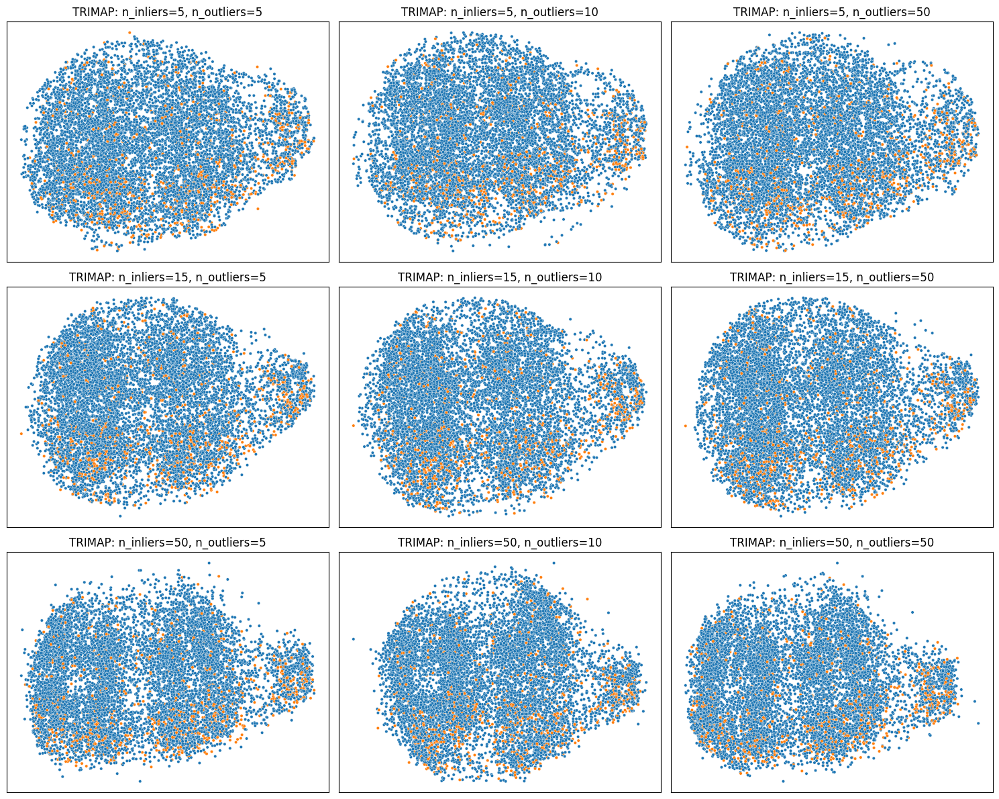

In [77]:
n_inliers = [5, 15, 50]
n_outliers = [5, 10, 50]

fig, axes = plt.subplots(len(n_inliers), len(n_outliers), figsize=(5*len(n_outliers), 4*len(n_inliers)))

for i, n in enumerate(n_inliers):
    for j, m in enumerate(n_outliers):
        X_emb = run_trimap(X_own_scaled, n_inliers=n, n_outliers=m)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"TRIMAP: n_inliers={n}, n_outliers={m}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

Sample size is smaller than the total number of assigned points, n_neighbors, n_MN, n_FP would be reorganized
Sample size cannot accommodate number of further pairs requested. n_FP will be reduced.
Sample size is smaller than the total number of assigned points, n_neighbors, n_MN, n_FP would be reorganized
Sample size cannot accommodate number of further pairs requested. n_FP will be reduced.
Sample size is smaller than the total number of assigned points, n_neighbors, n_MN, n_FP would be reorganized


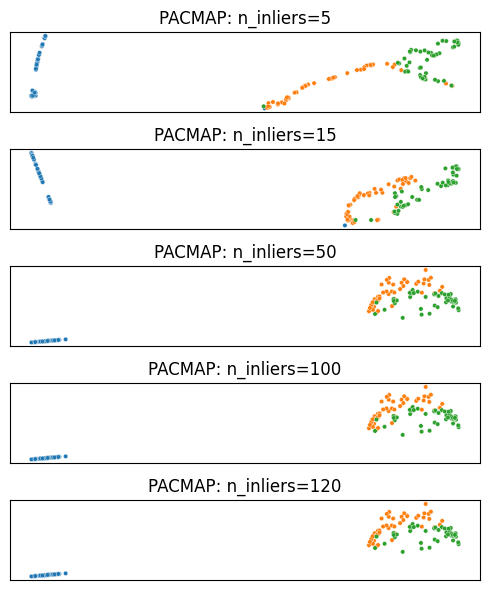

In [78]:
n_neighbors = [5, 15, 50, 100, 120]

fig, axes = plt.subplots(len(n_neighbors), figsize=(len(n_neighbors), 6))

for i, n in enumerate(n_neighbors):
    X_emb = run_pacmap(X_iris_scaled, n_neighbors=n)
    ax = axes[i]
    sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
    ax.set_title(f"PACMAP: n_inliers={n}")
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

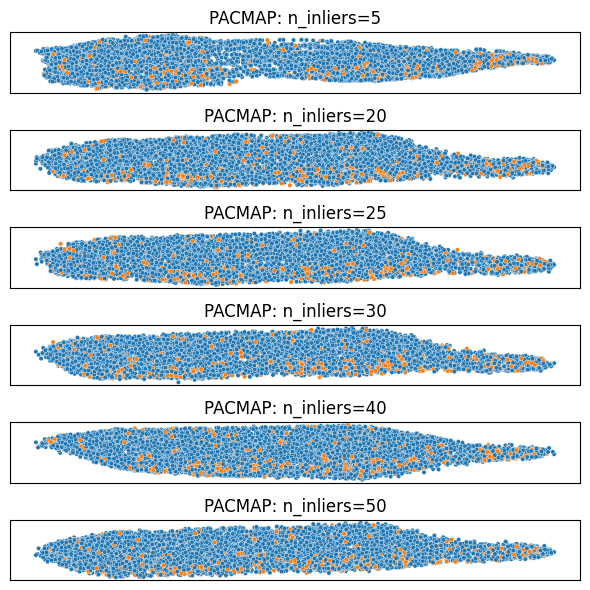

In [79]:
n_neighbors = [5, 20, 25, 30, 40, 50]

fig, axes = plt.subplots(len(n_neighbors), figsize=(len(n_neighbors), 6))

for i, n in enumerate(n_neighbors):
    X_emb = run_pacmap(X_own_scaled, n_neighbors=n)
    ax = axes[i]
    sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
    ax.set_title(f"PACMAP: n_inliers={n}")
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

Calculating PHATE...
  Running PHATE on 150 observations and 4 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculating affinities...
  Calculating optimal t...
    Automatically selected t = 21
  Calculated optimal t in 0.01 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by 1.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.09 seconds.
Calculated PHATE in 0.12 seconds.
Calculating PHATE...
  Running PHATE on 150 observations and 4 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculating affinities...
  Calculating optimal t...
    Automatically selected t = 22
  Calculated optimal t in 0.01 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...


g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\graphtools\graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\graphtools\graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


    SGD-MDS may not have converged: stress changed by -1.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.09 seconds.
Calculated PHATE in 0.12 seconds.
Calculating PHATE...
  Running PHATE on 150 observations and 4 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculating affinities...
  Calculating optimal t...
    Automatically selected t = 14
  Calculated optimal t in 0.01 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -1.2% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.10 seconds.
Calculated PHATE in 0.12 seconds.
Calculating PHATE...
  Running PHATE on 150 observations and 4 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculating affinities...
  Calculating optimal t...
    Automatically selecte

g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\graphtools\graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\graphtools\graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


  Calculated metric MDS in 0.09 seconds.
Calculated PHATE in 0.12 seconds.
Calculating PHATE...
  Running PHATE on 150 observations and 4 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculating affinities...
  Calculating optimal t...
    Automatically selected t = 8
  Calculated optimal t in 0.01 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -1.2% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.09 seconds.
Calculated PHATE in 0.12 seconds.
Calculating PHATE...
  Running PHATE on 150 observations and 4 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculating affinities...
  Calculating optimal t...
    Automatically selected t = 4
  Calculated optimal t in 0.01 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...


g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\graphtools\graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\graphtools\graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


    SGD-MDS may not have converged: stress changed by -2.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.10 seconds.
Calculated PHATE in 0.13 seconds.


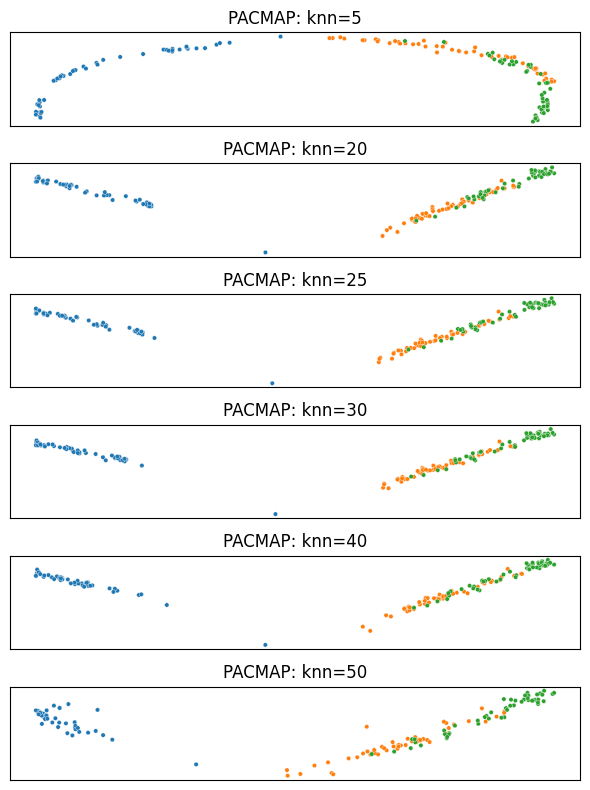

In [80]:
knn = [5, 20, 25, 30, 40, 50]

fig, axes = plt.subplots(len(knn), figsize=(len(knn), 8))

for i, n in enumerate(knn):
    X_emb = run_phate(X_iris_scaled, knn=n)
    ax = axes[i]
    sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
    ax.set_title(f"PACMAP: knn={n}")
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

Calculating PHATE...
  Running PHATE on 10000 observations and 7 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculated KNN search in 0.31 seconds.
    Calculating affinities...
    Calculated affinities in 0.12 seconds.
  Calculated graph and diffusion operator in 0.44 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 0.51 seconds.
    Calculating KMeans...
    Calculated KMeans in 2.61 seconds.
  Calculated landmark operator in 3.12 seconds.
  Calculating optimal t...
    Automatically selected t = 56
  Calculated optimal t in 1.65 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.46 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 1.90 seconds.
Calculated PHATE in 7.97 seconds.
Calculating PHATE...
  Running PHATE on 10000 observations and 7 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculated KNN sear

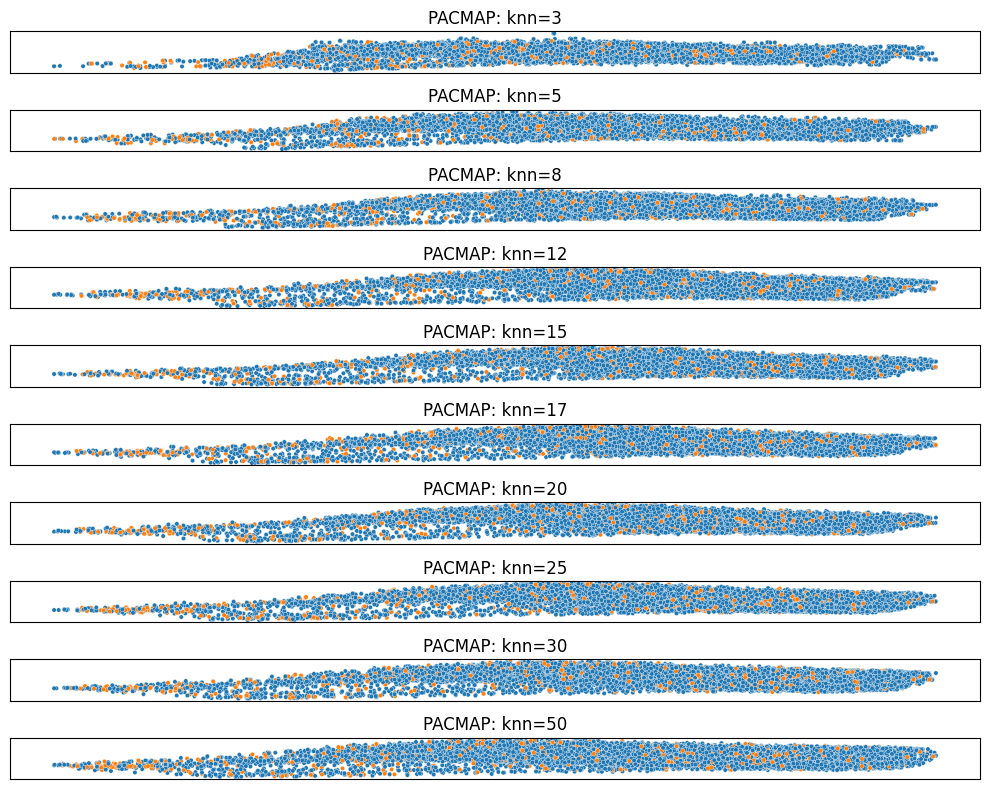

In [81]:
knn = [3, 5, 8, 12, 15, 17, 20, 25, 30, 50]

fig, axes = plt.subplots(len(knn), figsize=(len(knn), 8))

for i, n in enumerate(knn):
    X_emb = run_phate(X_own_scaled, knn=n)
    ax = axes[i]
    sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
    ax.set_title(f"PACMAP: knn={n}")
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

Обычно структура UMAP меняется плавнее, кластеры остаются узнаваемыми при разумном диапазоне параметров.

*Задача* Аналогично нужно сделать по одной строке графиков для TriMAP, PaCMAP, PHATE с варьированием ключевого параметра (количество соседей или похожий гиперпараметр) и показать, насколько устойчив рисунок.



| Метод  | Скорость на больших данных                   | Локальное разделение              | Глобальная структура                            | Чувствительность к параметрам                         | Комментарий                                        |
| ------ | -------------------------------------------- | --------------------------------- | ----------------------------------------------- | ----------------------------------------------------- | -------------------------------------------------- |
| t‑SNE  | Низкая l                    | Отличное                   | Слабая                                   | Высокая (perplexity, lr, random_state) aicompetence+2 | Хорошо для локальных кластеров, тяжёлый тюнинг     |
| UMAP   | Высокая l                   | Очень хорошее   | Лучшая, чем у t‑SNE           | Ниже, чем у t‑SNE aicompetence+2                      | Хороший баланс локал/глобал, удобен в практике     |
| TriMAP | Средняя                              | Хорошее                   | Сильный упор на глобальную структуру    | Умеренная                                     | Лучше показывает относительное положение кластеров |
| PaCMAP | Средняя                               | Отличное                   | Хорошее                                  | Умеренная                                      | Часто даёт чёткие кластеры и форму многобразия     |
| PHATE  | Средняя/низкая (зависит от размера)   | Хорошее        | Очень хорошее, особенно для траекторий   | Умеренная                          | Сильный метод для непрерывных переходов            |

# Варианты препроцессинга
*Задача* — явно сравнить, как UMAP и t‑SNE реагируют на разные варианты нормировки и отбора признаков.

## Определяем три сценария
Без масштабирования (сырой набор признаков).

StandardScaler (z‑нормировка).

MinMaxScaler + отбор признаков по дисперсии (эмуляция feature selection).

Задание. Проделать все три сценария. Обучить все модели при разных сценария кластеризации. 
Нужно в результате:
1. описать, какие признаки были отброшены и почему это может влиять на качество кластеризации во вложенном пространстве.
1. сравнить вычислительное время и сделать вывод о масштабируемости методов
1. изменить гиперпараметры (perplexity, n_neighbors, min_dist) и исследовать совместное влияние гиперпараметров и препроцессинга на структуру кластеров.


In [82]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import VarianceThreshold

X_own_scaled_minmax = MinMaxScaler().fit_transform(X_own)

selector = VarianceThreshold(threshold=0.02)
some_X_own_scaled_minmax = selector.fit_transform(X_own_scaled_minmax)

In [83]:
selected_indices = np.where(selector.get_support())[0]
dropped_indices = np.where(~selector.get_support())[0]

In [84]:
feature_names = df.columns.tolist()

selected_features = [feature_names[i] for i in selected_indices]
dropped_features = [feature_names[i] for i in dropped_indices]

print("Оставленные признаки:", selected_features)
print("Отброшенные признаки:", dropped_features)

Оставленные признаки: ['Age', 'CGPA', 'Sleep_Duration', 'Study_Hours', 'Social_Media_Hours', 'Physical_Activity', 'Stress_Level']
Отброшенные признаки: []


In [85]:
some_X_own_scaled_minmax.shape

(10000, 7)

In [86]:
import datetime

## T-SNE

Base data


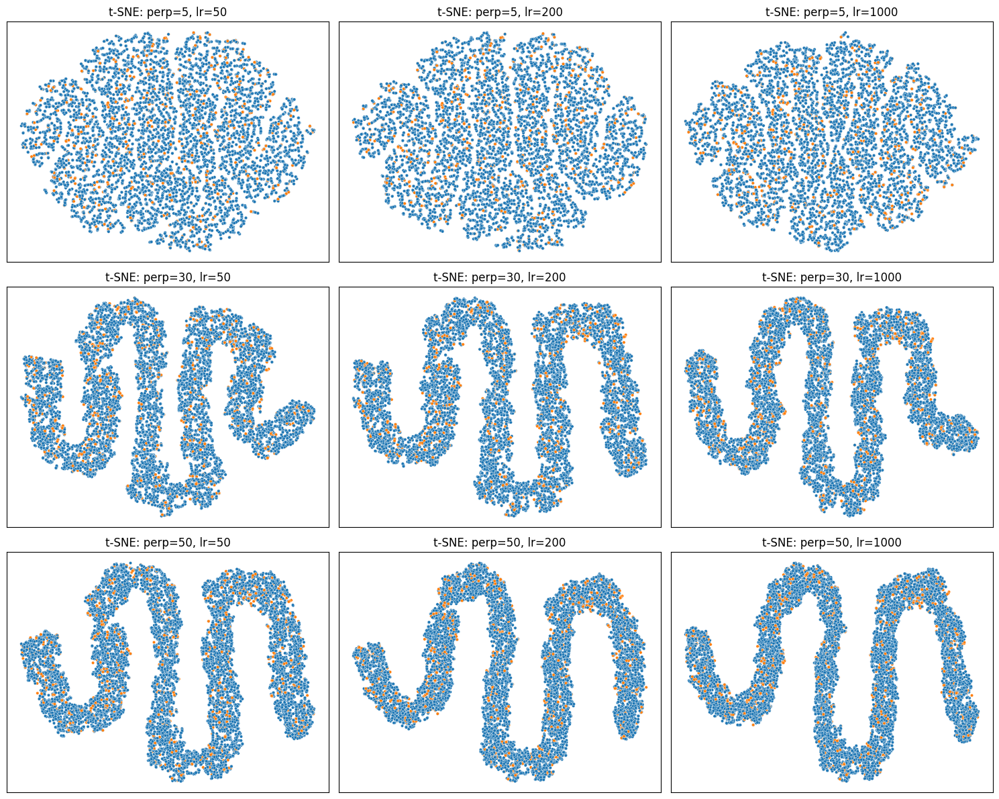

Time work: 0:03:02.334830


In [87]:
perplexities = [5, 30, 50]
lrs = [50, 200, 1000]

print('Base data')

startTime = datetime.datetime.now()

fig, axes = plt.subplots(len(perplexities), len(lrs), figsize=(5*len(lrs), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(lrs):
        X_emb = run_tsne(X_own, random_state=42, perplexity=perp, learning_rate=lr)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"t-SNE: perp={perp}, lr={lr}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

endTime = datetime.datetime.now()
print('Time work:', endTime - startTime)

StandardScaler


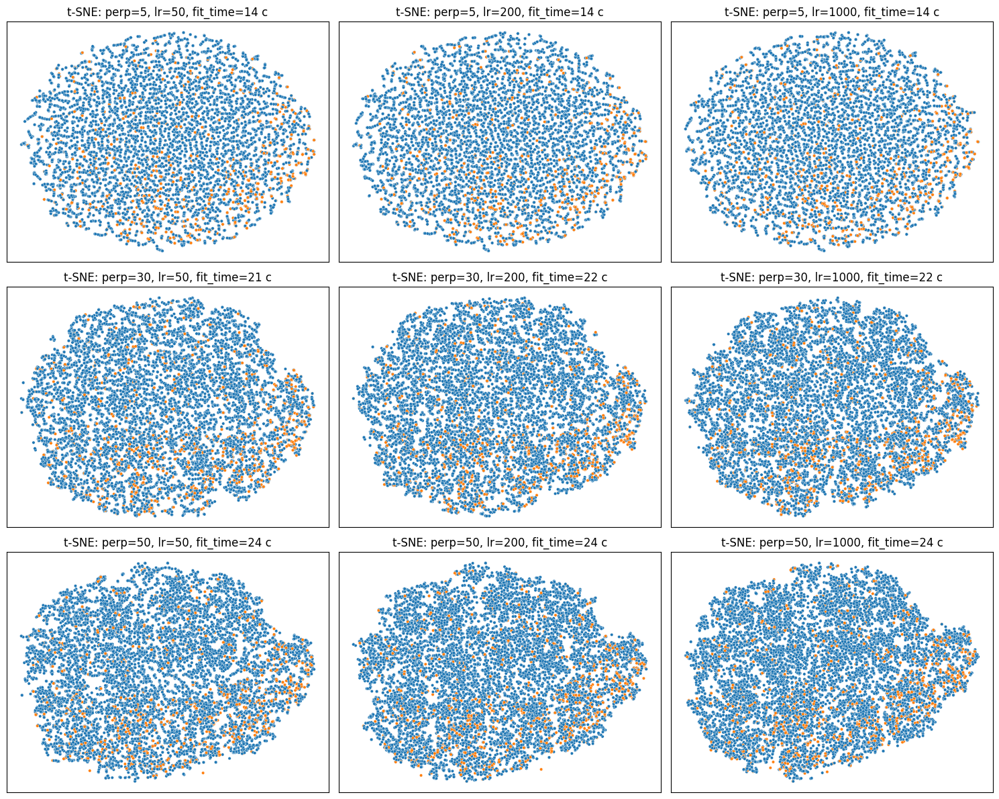

Time work: 0:00:25.739013


In [88]:
perplexities = [5, 30, 50]
lrs = [50, 200, 1000]

print('StandardScaler')

startTime = datetime.datetime.now()

fig, axes = plt.subplots(len(perplexities), len(lrs), figsize=(5*len(lrs), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(lrs):
        startTime = datetime.datetime.now()
        X_emb = run_tsne(X_own_scaled, random_state=42, perplexity=perp, learning_rate=lr)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        endTime = datetime.datetime.now()
        ax.set_title(f"t-SNE: perp={perp}, lr={lr}, fit_time={(endTime-startTime).seconds} с")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

endTime = datetime.datetime.now()
print('Time work:', endTime - startTime)

MinMaxScaler + feature selection


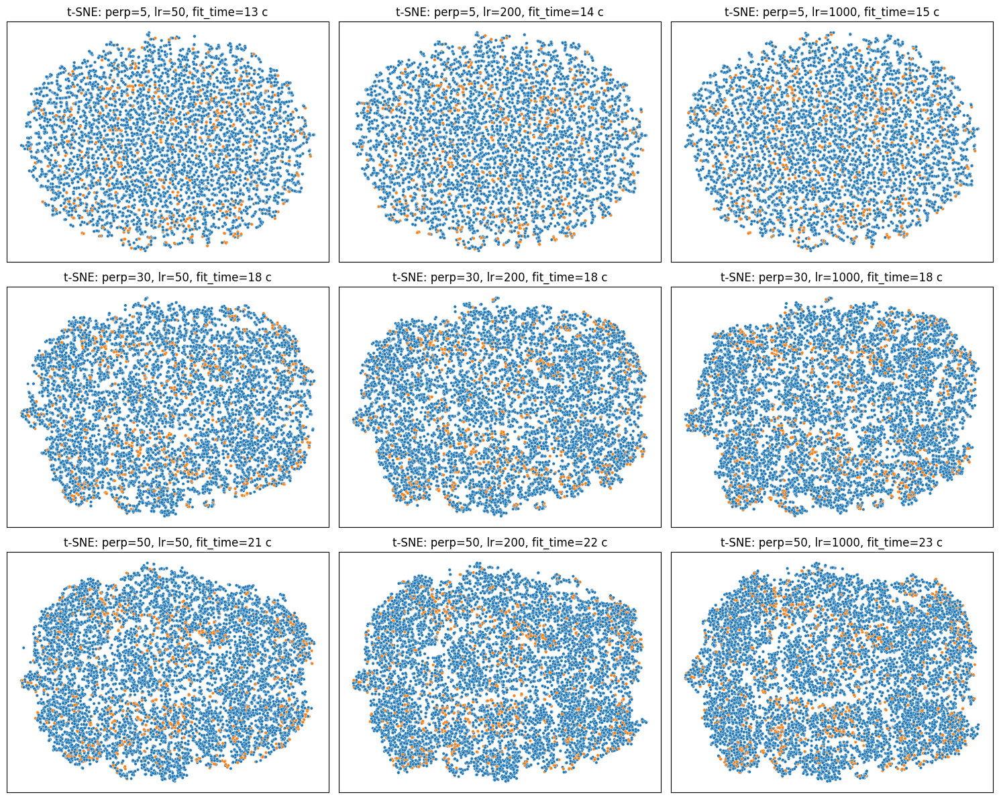

Time work: 0:00:24.089414


In [89]:
perplexities = [5, 30, 50]
lrs = [50, 200, 1000]

print('MinMaxScaler + feature selection')

startTime = datetime.datetime.now()

fig, axes = plt.subplots(len(perplexities), len(lrs), figsize=(5*len(lrs), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(lrs):
        startTime = datetime.datetime.now()
        X_emb = run_tsne(some_X_own_scaled_minmax, random_state=42, perplexity=perp, learning_rate=lr)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        endTime = datetime.datetime.now()
        ax.set_title(f"t-SNE: perp={perp}, lr={lr}, fit_time={(endTime-startTime).seconds} c")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

endTime = datetime.datetime.now()
print('Time work:', endTime - startTime)

## UMAP

Base data
Сырые данные:


g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 ove

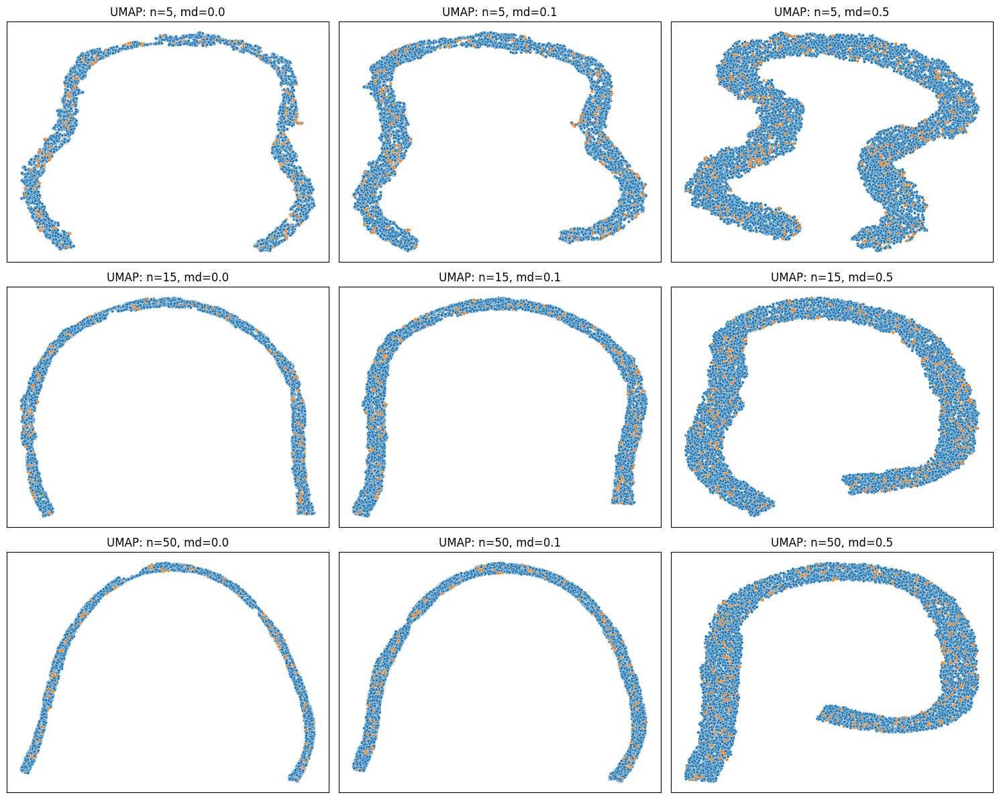

Time work: 0:01:24.420726


In [90]:
n_neighbors = [5, 15, 50]
md = [0.0, 0.1, 0.5]

print('Base data')

startTime = datetime.datetime.now()

fig, axes = plt.subplots(len(n_neighbors), len(md), figsize=(5*len(md), 4*len(n_neighbors)))

print('Сырые данные:')
for i, n in enumerate(n_neighbors):
    for j, m in enumerate(md):
        X_emb = run_umap(X_own, random_state=42, n_neighbors=n, min_dist=m)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"UMAP: n={n}, md={m}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

endTime = datetime.datetime.now()
print('Time work:', endTime - startTime)

StandardScaler


g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 ove

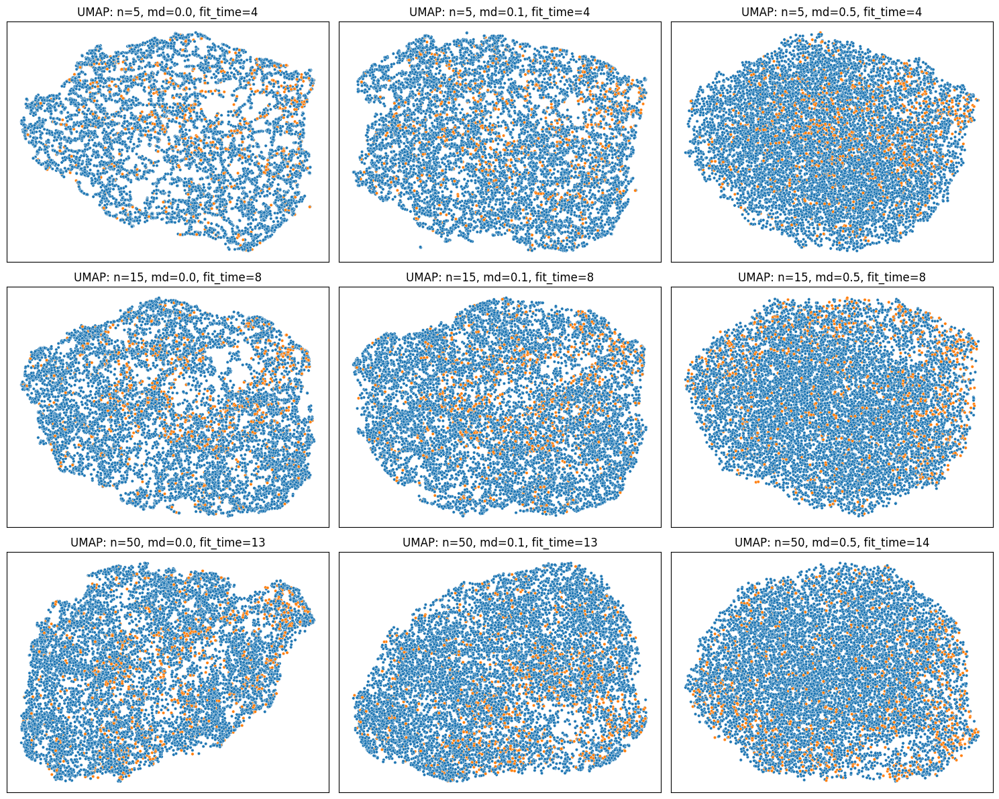

In [91]:
n_neighbors = [5, 15, 50]
md = [0.0, 0.1, 0.5]

print('StandardScaler')

fig, axes = plt.subplots(len(n_neighbors), len(md), figsize=(5*len(md), 4*len(n_neighbors)))

for i, n in enumerate(n_neighbors):
    for j, m in enumerate(md):
        startTime = datetime.datetime.now()
        X_emb = run_umap(X_own_scaled, random_state=42, n_neighbors=n, min_dist=m)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        endTime = datetime.datetime.now()
        ax.set_title(f"UMAP: n={n}, md={m}, fit_time={(endTime-startTime).seconds}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

MinMaxScaler


g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
g:\University\Магистратура\Кластеризация и понижение размерности\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 ove

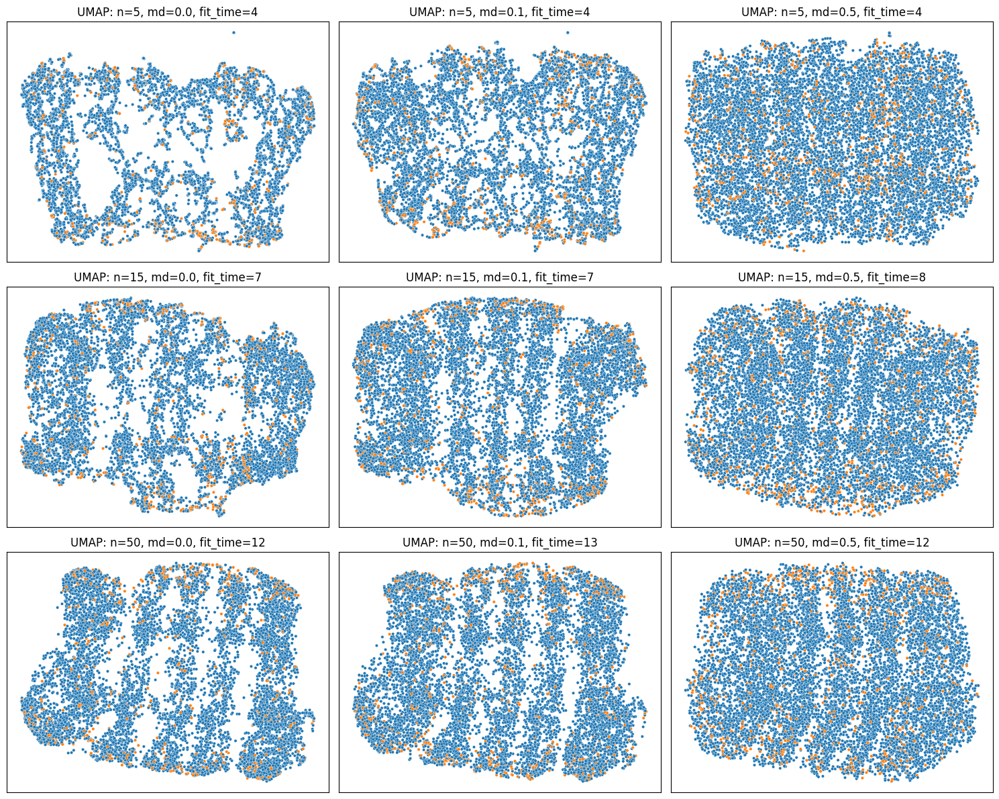

In [92]:
n_neighbors = [5, 15, 50]
md = [0.0, 0.1, 0.5]

print('MinMaxScaler')

fig, axes = plt.subplots(len(n_neighbors), len(md), figsize=(5*len(md), 4*len(n_neighbors)))

for i, n in enumerate(n_neighbors):
    for j, m in enumerate(md):
        startTime = datetime.datetime.now()
        X_emb = run_umap(some_X_own_scaled_minmax, random_state=42, n_neighbors=n, min_dist=m)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        endTime = datetime.datetime.now()
        ax.set_title(f"UMAP: n={n}, md={m}, fit_time={(endTime-startTime).seconds}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()